# 接触对象：接触与伙伴

接触对象为其他浓相链；零伙伴保留，无选中链的帧缺失。参数以保存结果为准。

在首个代码单元选择OBJECT：central_chain为每帧中心链，dense_chains为全部浓相链。


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project among the working directory and its parents.
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations.yaml").is_file()), None
)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the project, or set ROOT explicitly")
sys.path.insert(0, str(ROOT))
from common import inputs
from common import results as files

CONFIG = ROOT / "simulations.yaml"
SELECTED = None  # None means all registered simulations.
OBJECT = "central_chain"  # central_chain / dense_chains
RESULTS_ROOT = ROOT / "03_results"
SIMULATIONS = inputs.select_simulations(CONFIG, SELECTED)
RESULTS = {s["id"]: files.completed(RESULTS_ROOT / s["id"] / "02_contacts/02_inter" / OBJECT) for s in SIMULATIONS}
SOURCES = {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()}
COLORS = {name: plt.get_cmap("tab10")(i % 10) for i, name in enumerate(RESULTS)}
FIGURES = ROOT / "05_plot/02_contacts/02_inter/figures" / OBJECT
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "svg.fonttype": "none",
        "pdf.fonttype": 42,
    }
)


def export(fig, name):
    for key, path in RESULTS.items():
        files.completed(path)
        if files.read_json(path / "metadata.json") != SOURCES[key]:
            raise ValueError("Results changed; restart and rerun the notebook")
    for extension in ("png", "pdf", "svg"):
        fig.savefig(FIGURES / f"{name}.{extension}", dpi=300, bbox_inches="tight")
    files.write_json(
        FIGURES / f"{name}.sources.json",
        {key: files.read_json(path / "metadata.json") for key, path in RESULTS.items()},
    )


,simulation_id,threshold,total_contacts_mean_frames,total_contacts_std_frames,total_contacts_count_frames,partner_count_mean_frames,partner_count_std_frames,partner_count_count_frames,contacts_per_partner_mean_frames,contacts_per_partner_std_frames,contacts_per_partner_count_frames,total_contacts_std_blocks,total_contacts_count_blocks,total_contacts_sem_blocks,partner_count_std_blocks,partner_count_count_blocks,partner_count_sem_blocks,contacts_per_partner_std_blocks,contacts_per_partner_count_blocks,contacts_per_partner_sem_blocks
0,A18_T260,1,94.702667,37.945761,750,8.642667,2.780879,750,11.119971,3.696336,749,9.559061,15,2.468139,0.871251,15,0.224956,0.685813,15,0.177076
1,A18_T260,5,94.702667,37.945761,750,5.782667,2.235045,750,16.930233,5.229169,745,9.559061,15,2.468139,0.651059,15,0.168103,0.650919,15,0.168067
2,A18_T260,10,94.702667,37.945761,750,3.544000,1.613547,750,28.836456,10.073244,738,9.559061,15,2.468139,0.387534,15,0.100061,1.767444,15,0.456352
3,B01_T260,1,135.053333,37.434301,750,12.376000,2.926325,750,11.146615,2.938316,750,5.491779,15,1.417971,0.463416,15,0.119653,0.254229,15,0.065642
4,B01_T260,5,135.053333,37.434301,750,8.314667,2.328708,750,16.694229,3.993996,750,5.491779,15,1.417971,0.428383,15,0.110608,0.593712,15,0.153296
5,B01_T260,10,135.053333,37.434301,750,5.233333,1.827752,750,27.430101,8.597912,748,5.491779,15,1.417971,0.290681,15,0.075053,1.392817,15,0.359624
6,B10_T260,1,127.592000,44.035839,750,9.249333,3.005197,750,14.314304,4.621259,749,13.407501,15,3.461802,1.098229,15,0.283561,0.802009,15,0.207078
7,B10_T260,5,127.592000,44.035839,750,6.501333,2.213413,750,20.285762,6.248857,748,13.407501,15,3.461802,0.737078,15,0.190313,0.947152,15,0.244554
8,B10_T260,10,127.592000,44.035839,750,4.604000,1.760488,750,29.119500,8.404066,744,13.407501,15,3.461802,0.592727,15,0.153042,1.441221,15,0.372122


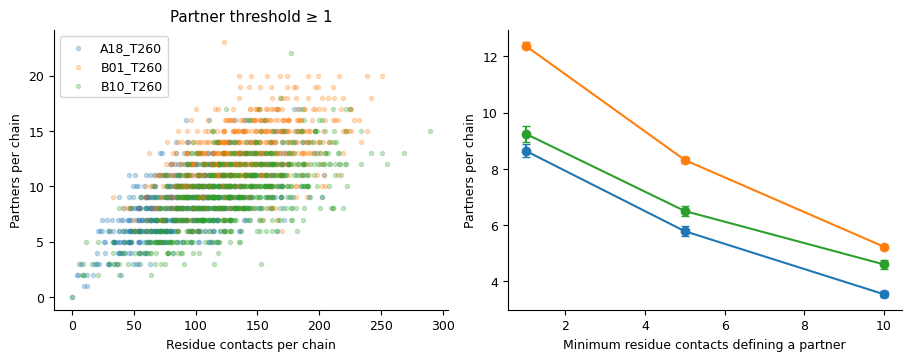

In [2]:
THRESHOLDS = sorted(
    set.intersection(*(set(meta["parameters"]["partner_thresholds"]) for meta in SOURCES.values()))
)
if not THRESHOLDS:
    raise ValueError("No shared thresholds among selected results")

frames = pd.concat(
    [pd.read_csv(p / "frame_means.csv") for p in RESULTS.values()], ignore_index=True
)
summary = pd.concat([pd.read_csv(p / "summary.csv") for p in RESULTS.values()], ignore_index=True)
display(summary)
PRIMARY_THRESHOLD = THRESHOLDS[0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
for name in RESULTS:
    points = frames[frames.simulation_id.eq(name) & frames.threshold.eq(PRIMARY_THRESHOLD)]
    axes[0].scatter(
        points.total_contacts, points.partner_count, s=9, alpha=0.25, color=COLORS[name], label=name
    )
    stat = summary[summary.simulation_id.eq(name)].sort_values("threshold")
    axes[1].errorbar(
        stat.threshold,
        stat.partner_count_mean_frames,
        yerr=stat.partner_count_sem_blocks,
        marker="o",
        capsize=3,
        color=COLORS[name],
        label=name,
    )
axes[0].set(
    xlabel="Residue contacts per chain",
    ylabel="Partners per chain",
    title=f"Partner threshold ≥ {PRIMARY_THRESHOLD}",
)
axes[1].set(xlabel="Minimum residue contacts defining a partner", ylabel="Partners per chain")
axes[0].legend()
export(fig, "contacts_and_partners")
plt.show()
